# PLASTIC WASTE AND RECYCLING ANALYTICS

Performed data cleaning, missing value handling, outlier detection, exploratory data analysis, and visualization on the Plastic waste and recycling  dataset using Pandas, Matplotlib, and Seaborn.

## Loading Dataset into Python Environment

Imported libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
waste_data=pd.read_csv(r"C:\Users\LENOVO\Desktop\Unique Occassio\DataSets\Waste_Management_and_Recycling_India_cleaned.csv")

Displayed the top 5 rows of the data

In [3]:
waste_data.head()

,city/district,waste_type,waste_generated_(tons/day),recycling_rate_(%),population_density_(people/km²),municipal_efficiency_score_(1_10),disposal_method,cost_of_waste_management_(₹/ton),awareness_campaigns_count,landfill_name,"landfill_location_(lat,_long)",landfill_capacity_(tons),year
0,Mumbai,Plastic,6610,68,11191,9,Composting,3056,14,Mumbai Landfill,"22.4265, 77.4931",45575,1970
1,Mumbai,Organic,1181,56,11191,5,Composting,2778,12,Mumbai Landfill,"22.4265, 77.4931",45575,1970
2,Mumbai,E-Waste,8162,53,11191,8,Incineration,3390,13,Mumbai Landfill,"22.4265, 77.4931",45575,1970
3,Mumbai,Construction,8929,56,11191,5,Landfill,1498,14,Mumbai Landfill,"22.4265, 77.4931",45575,1970
4,Mumbai,Hazardous,5032,44,11191,7,Recycling,2221,16,Mumbai Landfill,"22.4265, 77.4931",45575,1970


Boolean filtering in Pandas to retain only rows where waste_type == 'plastic'

In [4]:
plastic_data=waste_data[waste_data['waste_type']=='Plastic']

In [5]:
plastic_data.head()

,city/district,waste_type,waste_generated_(tons/day),recycling_rate_(%),population_density_(people/km²),municipal_efficiency_score_(1_10),disposal_method,cost_of_waste_management_(₹/ton),awareness_campaigns_count,landfill_name,"landfill_location_(lat,_long)",landfill_capacity_(tons),year
0,Mumbai,Plastic,6610,68,11191,9,Composting,3056,14,Mumbai Landfill,"22.4265, 77.4931",45575,1970
5,Mumbai,Plastic,7456,73,11191,9,Landfill,3195,6,Mumbai Landfill,"22.4265, 77.4931",45575,1970
10,Mumbai,Plastic,6932,81,11191,10,Incineration,2543,16,Mumbai Landfill,"22.4265, 77.4931",45575,1970
15,Mumbai,Plastic,2501,41,11191,9,Recycling,1194,4,Mumbai Landfill,"22.4265, 77.4931",45575,1970
20,Mumbai,Plastic,6569,48,11191,5,Landfill,4287,16,Mumbai Landfill,"22.4265, 77.4931",45575,1970


Shape of the Data

In [6]:
plastic_data.shape

(170, 13)

Statistical Summary of data

In [7]:
plastic_data.describe().T

,count,mean,std,min,25%,50%,75%,max
waste_generated_(tons/day),170.0,5557.152941,2583.561211,558.0,3589.00,5501.5,7829.75,9980.0
recycling_rate_(%),170.0,58.141176,15.729333,30.0,46.00,59.0,72.75,84.0
population_density_(people/km²),170.0,13489.705882,6646.757832,2335.0,7927.00,12579.5,19087.00,24032.0
municipal_efficiency_score_(1_10),170.0,7.570588,1.776995,5.0,6.00,8.0,9.00,10.0
cost_of_waste_management_(₹/ton),170.0,2834.394118,1308.718816,509.0,1758.25,2876.0,4029.75,4999.0
awareness_campaigns_count,170.0,9.329412,6.137263,0.0,4.00,11.0,14.75,20.0
landfill_capacity_(tons),170.0,58934.617647,19459.522456,22690.0,45575.00,61038.5,71127.00,98646.0
year,170.0,1970.000000,0.000000,1970.0,1970.00,1970.0,1970.00,1970.0


Information about the data

In [8]:
plastic_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 170 entries, 0 to 845
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   city/district                      170 non-null    str  
 1   waste_type                         170 non-null    str  
 2   waste_generated_(tons/day)         170 non-null    int64
 3   recycling_rate_(%)                 170 non-null    int64
 4   population_density_(people/km²)    170 non-null    int64
 5   municipal_efficiency_score_(1_10)  170 non-null    int64
 6   disposal_method                    170 non-null    str  
 7   cost_of_waste_management_(₹/ton)   170 non-null    int64
 8   awareness_campaigns_count          170 non-null    int64
 9   landfill_name                      170 non-null    str  
 10  landfill_location_(lat,_long)      170 non-null    str  
 11  landfill_capacity_(tons)           170 non-null    int64
 12  year                             

Found the number of unique values of each column

In [9]:
plastic_data.nunique()

city/district                         34
waste_type                             1
waste_generated_(tons/day)           169
recycling_rate_(%)                    53
population_density_(people/km²)       33
municipal_efficiency_score_(1_10)      6
disposal_method                        4
cost_of_waste_management_(₹/ton)     167
awareness_campaigns_count             21
landfill_name                         34
landfill_location_(lat,_long)         34
landfill_capacity_(tons)              34
year                                   1
dtype: int64

In [10]:
for i in plastic_data.columns:
    print(i)
    print(plastic_data[i].unique())
    print("-"*50)
    print("\n")

city/district
<ArrowStringArray>
[            'Mumbai',              'Delhi',          'Bengaluru',
            'Chennai',            'Kolkata',          'Hyderabad',
               'Pune',          'Ahmedabad',             'Jaipur',
            'Lucknow',              'Surat',             'Kanpur',
             'Nagpur',              'Patna',             'Bhopal',
 'Thiruvananthapuram',             'Indore',           'Vadodara',
           'Guwahati',         'Coimbatore',             'Ranchi',
           'Amritsar',            'Jodhpur',           'Varanasi',
           'Ludhiana',               'Agra',             'Meerut',
             'Nashik',             'Rajkot',            'Madurai',
           'Jabalpur',          'Allahabad',      'Visakhapatnam',
            'Gwalior']
Length: 34, dtype: str
--------------------------------------------------


waste_type
<ArrowStringArray>
['Plastic']
Length: 1, dtype: str
--------------------------------------------------


waste_generate

## Missing Values

Checking for Null values

In [11]:
plastic_data.isna().sum()

city/district                        0
waste_type                           0
waste_generated_(tons/day)           0
recycling_rate_(%)                   0
population_density_(people/km²)      0
municipal_efficiency_score_(1_10)    0
disposal_method                      0
cost_of_waste_management_(₹/ton)     0
awareness_campaigns_count            0
landfill_name                        0
landfill_location_(lat,_long)        0
landfill_capacity_(tons)             0
year                                 0
dtype: int64

All columns are filled and nothing to handle

## Correlaton Matrix

<Axes: >

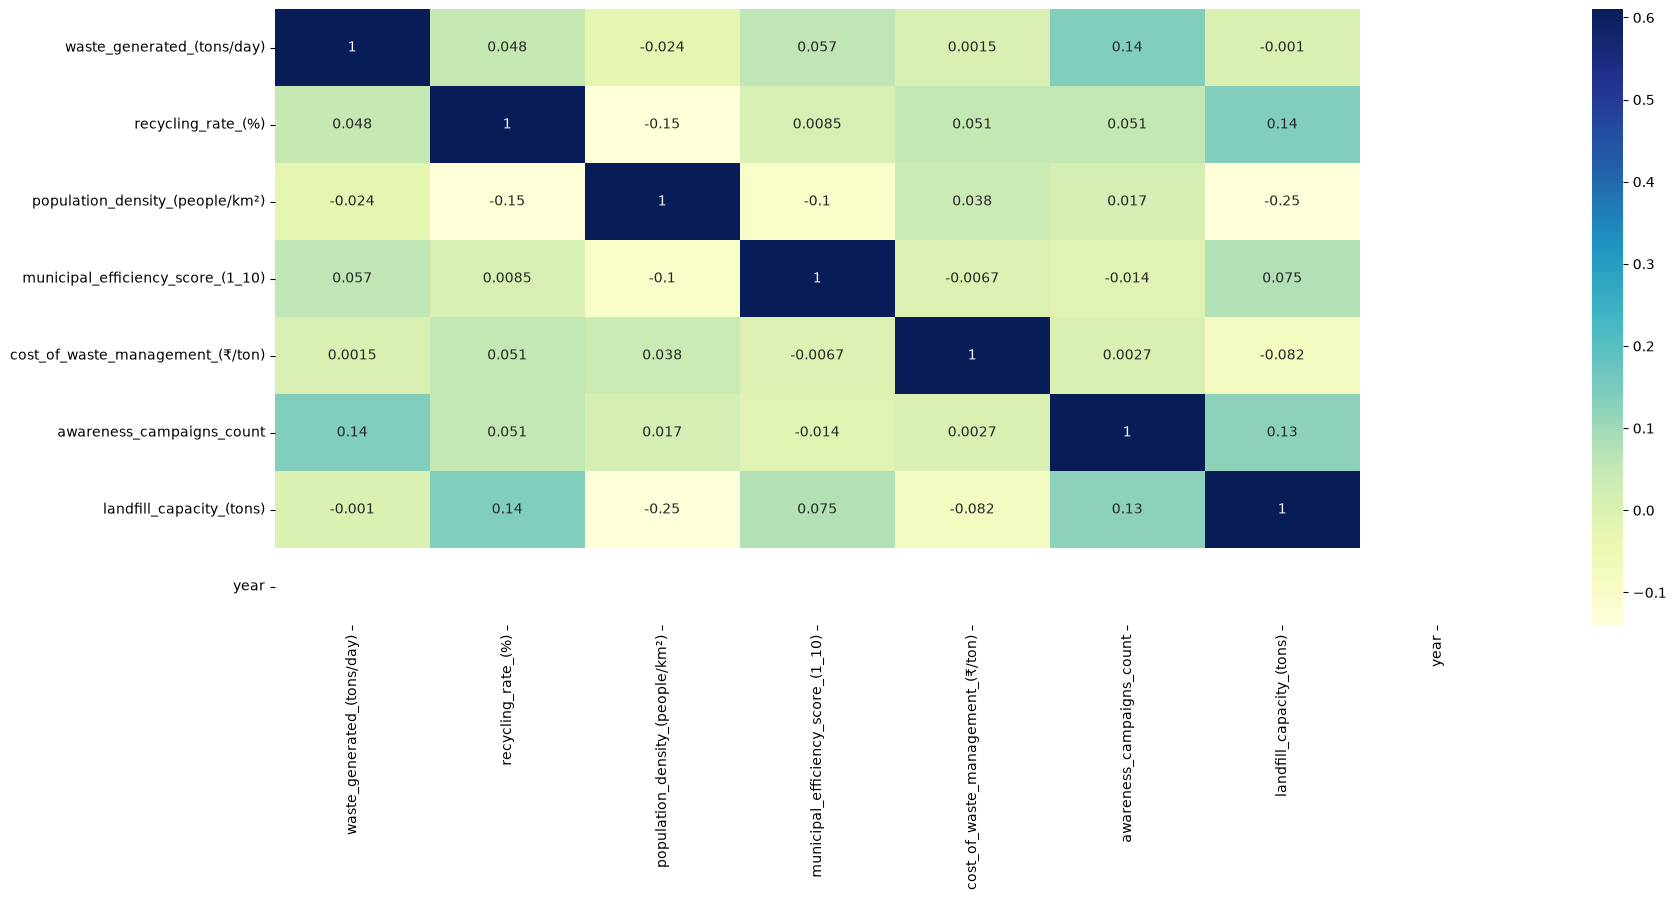

In [12]:
# Select numerical columns
numeric_data = plastic_data.select_dtypes(include='number')

corrmatrix=numeric_data.corr()
plt.subplots(figsize=(20,8))
sns.heatmap(corrmatrix,annot=True,vmin=-0.14,vmax=0.61,cmap='YlGnBu')

## Feature Engineering

In [13]:
plastic_data.drop(['waste_type','population_density_(people/km²)','municipal_efficiency_score_(1_10)','landfill_location_(lat,_long)','year'], axis=1, inplace=True)

Add column that shows actual quantity of plastic waste recycled per day.

In [14]:
plastic_data['recycled_waste'] = (
    plastic_data['waste_generated_(tons/day)'] *
    plastic_data['recycling_rate_(%)'] / 100
)

Create categories based on the recycling rate.

In [15]:
plastic_data['recycling_category'] = pd.cut(
    plastic_data['recycling_rate_(%)'],
    bins=[0, 40, 60, 80, 100],
    labels=['Poor', 'Average', 'Good', 'Excellent'],
    include_lowest=True
)

Display sample 10 data

In [16]:
plastic_data.sample(10)

,city/district,waste_generated_(tons/day),recycling_rate_(%),disposal_method,cost_of_waste_management_(₹/ton),awareness_campaigns_count,landfill_name,landfill_capacity_(tons),recycled_waste,recycling_category
15,Mumbai,2501,41,Recycling,1194,4,Mumbai Landfill,45575,1025.41,Average
820,Visakhapatnam,7054,62,Composting,1978,10,Visakhapatnam Landfill,48016,4373.48,Good
310,Nagpur,2872,47,Incineration,1084,16,Nagpur Landfill,49830,1349.84,Average
660,Meerut,4686,69,Composting,3910,8,Meerut Landfill,56989,3233.34,Good
575,Varanasi,8397,75,Landfill,1994,0,Varanasi Landfill,79314,6297.75,Good
610,Ludhiana,6762,72,Composting,1588,10,Ludhiana Landfill,69241,4868.64,Good
405,Indore,9082,78,Incineration,4800,16,Indore Landfill,61142,7083.96,Good
385,Thiruvananthapuram,7306,67,Landfill,1198,3,Thiruvananthapuram Landfill,30373,4895.02,Good
125,Hyderabad,5089,66,Recycling,1103,10,Hyderabad Landfill,34239,3358.74,Good
555,Jodhpur,8803,59,Composting,2822,11,Jodhpur Landfill,45318,5193.77,Average


## Outlier Handling

Checking Outliers

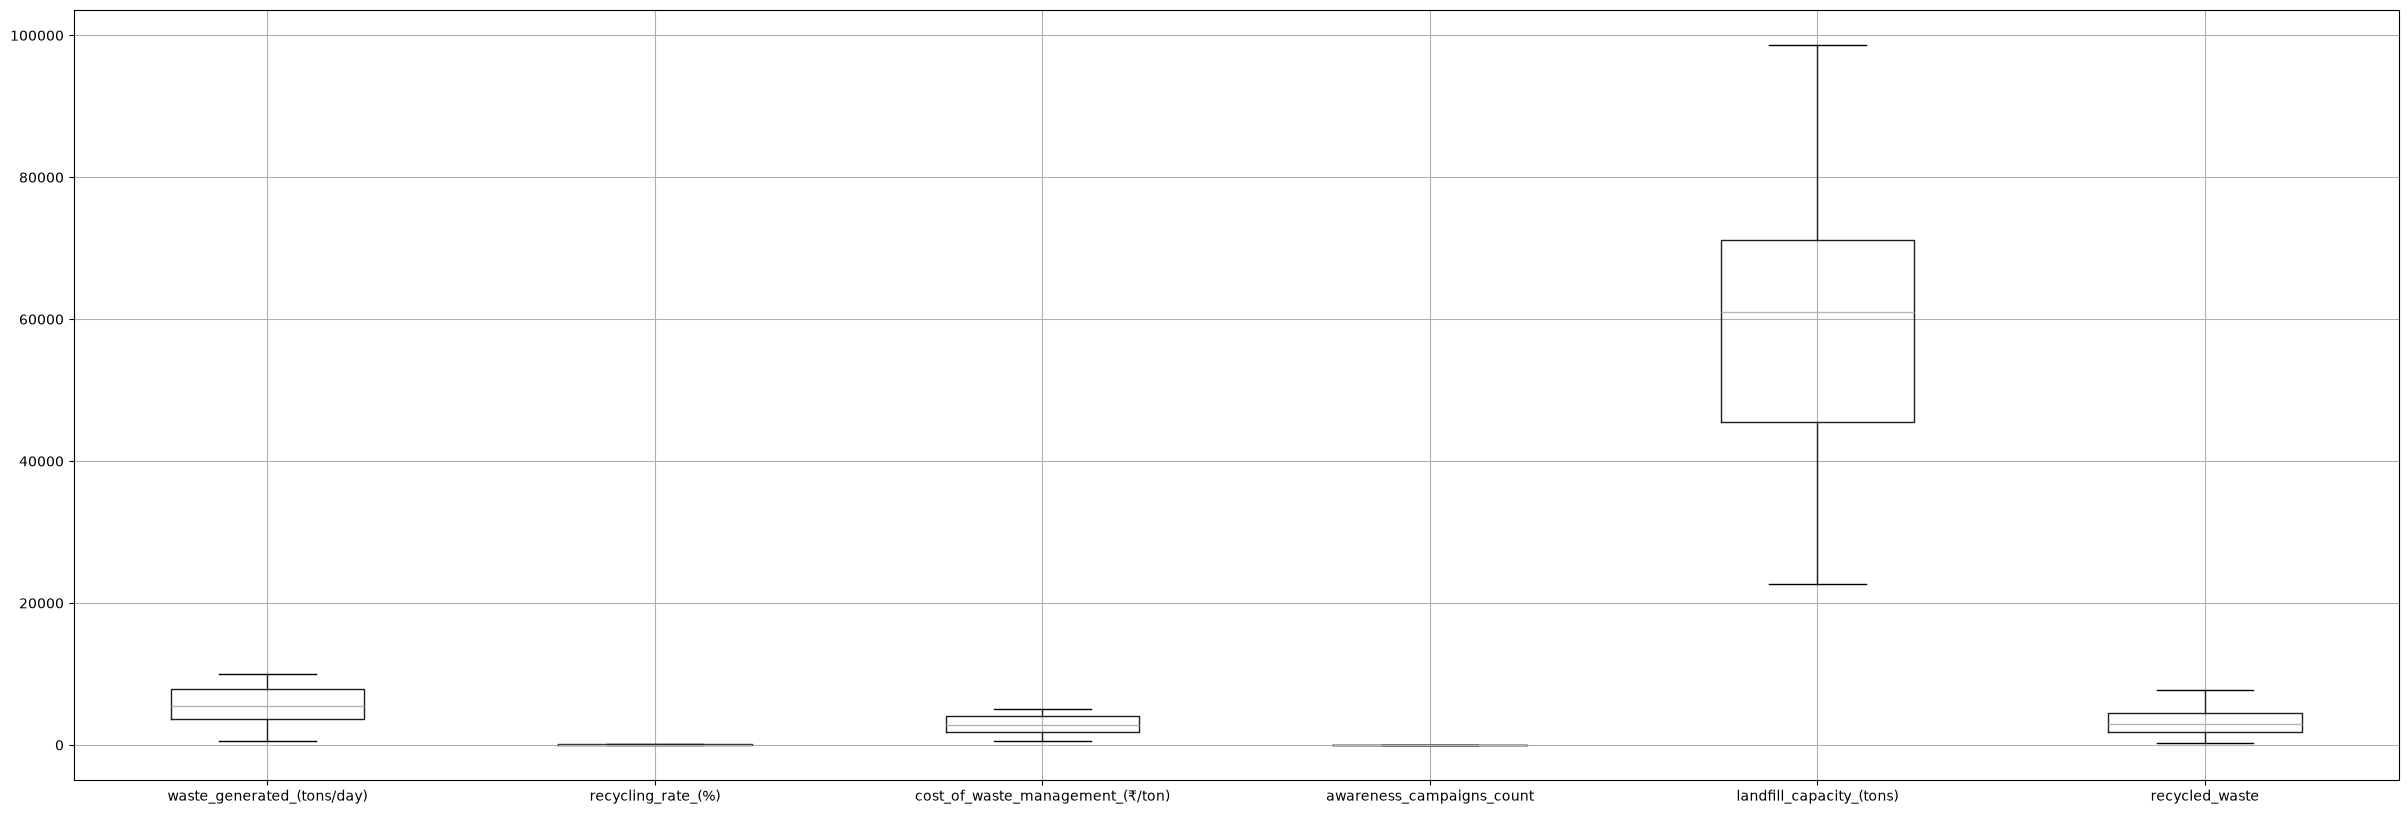

In [17]:
plt.figure(figsize=(30,10))
plastic_data.boxplot()
plt.show()

No outliers were identified in the selected numerical features. Therefore, no outlier removal or replacement was necessary

## Data Visualization

### Univarite Analysis

In [18]:
plastic_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 170 entries, 0 to 845
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   city/district                     170 non-null    str     
 1   waste_generated_(tons/day)        170 non-null    int64   
 2   recycling_rate_(%)                170 non-null    int64   
 3   disposal_method                   170 non-null    str     
 4   cost_of_waste_management_(₹/ton)  170 non-null    int64   
 5   awareness_campaigns_count         170 non-null    int64   
 6   landfill_name                     170 non-null    str     
 7   landfill_capacity_(tons)          170 non-null    int64   
 8   recycled_waste                    170 non-null    float64 
 9   recycling_category                170 non-null    category
dtypes: category(1), float64(1), int64(5), str(3)
memory usage: 18.1 KB


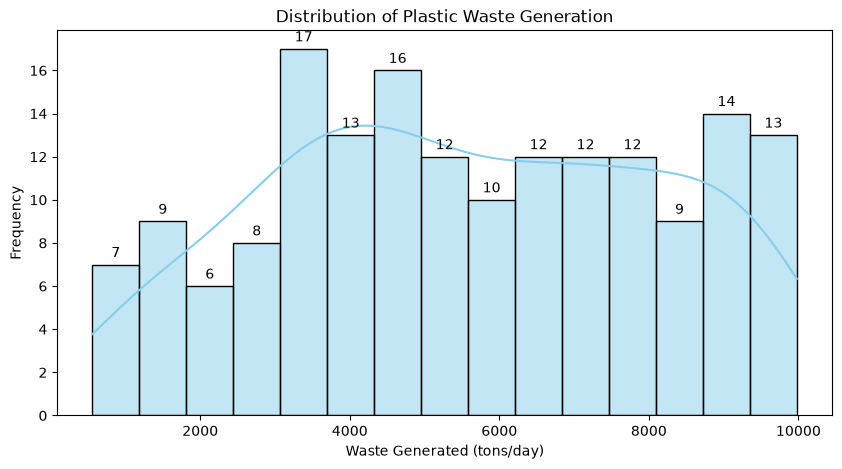

In [19]:
plt.figure(figsize=(10, 5))

ax=sns.histplot(
    data=plastic_data,
    x='waste_generated_(tons/day)',
    bins=15,
    kde=True,
    color='skyblue'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of Plastic Waste Generation')
plt.xlabel('Waste Generated (tons/day)')
plt.ylabel('Frequency')

plt.show()

* Around 500 tons to 10000 tons of waste are generated in a day
* Only limited number of cities produce less than 3000 tons - Only 17.65%
* Most of the Cities produces wastes from 3000 to 6000 tons of waste

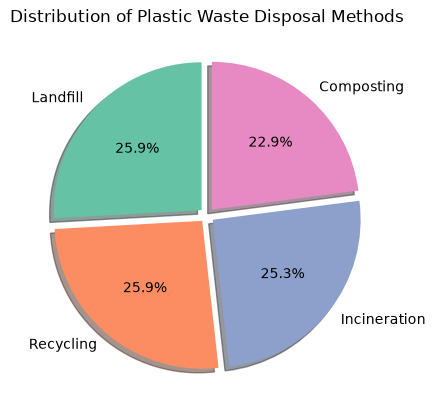

In [20]:
disposal_counts = plastic_data['disposal_method'].value_counts()
plt.pie(
    disposal_counts,
    labels=disposal_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2'),
    explode=[0.05] * len(disposal_counts),
    shadow=True
)

plt.title('Distribution of Plastic Waste Disposal Methods')
plt.show()

* Most of the cities uses recycling and landfill methods for waste disposal - 25.9%
* Composting is minimaly used method for waste disposal - 22.9%%
* Incineration is used by 25.3% of cities.

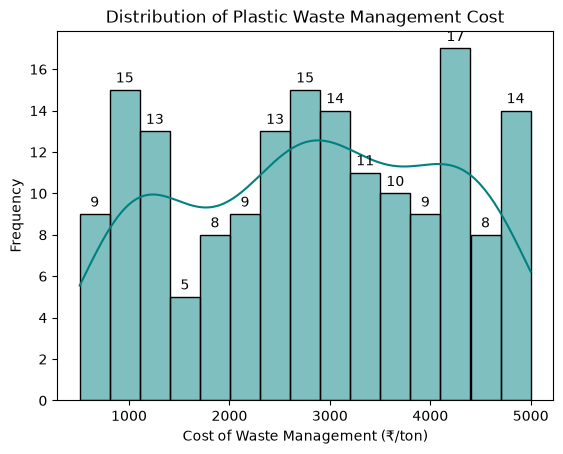

In [21]:
ax=sns.histplot(
    data=plastic_data,
    x='cost_of_waste_management_(₹/ton)',
    bins=15,
    kde=True,
    color='teal'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of Plastic Waste Management Cost')
plt.xlabel('Cost of Waste Management (₹/ton)')
plt.ylabel('Frequency')

plt.show()

* Cost of the waste management starts from 300 to 5000 per ton

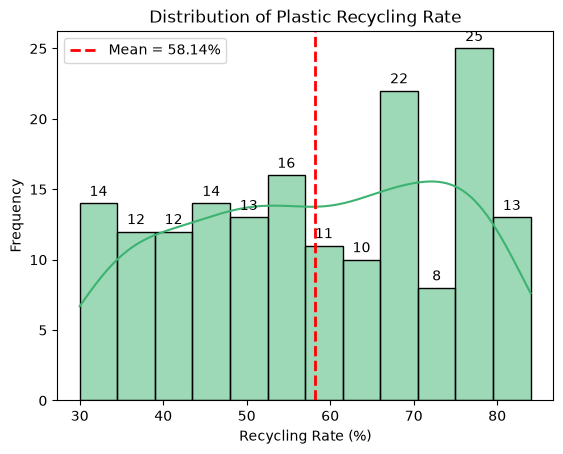

In [22]:
ax=sns.histplot(
    data=plastic_data,
    x='recycling_rate_(%)',
    bins=12,
    kde=True,
    color='mediumseagreen'
)

avg = plastic_data['recycling_rate_(%)'].mean()

plt.axvline(
    avg,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean = {avg:.2f}%'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of Plastic Recycling Rate')
plt.xlabel('Recycling Rate (%)')
plt.ylabel('Frequency')
plt.legend()

plt.show()

* Minimum recycling rate - 30%
* Maximum recycling rate -  84%
* Average recycling rate - 58.14%
* Range - 54 percentage points

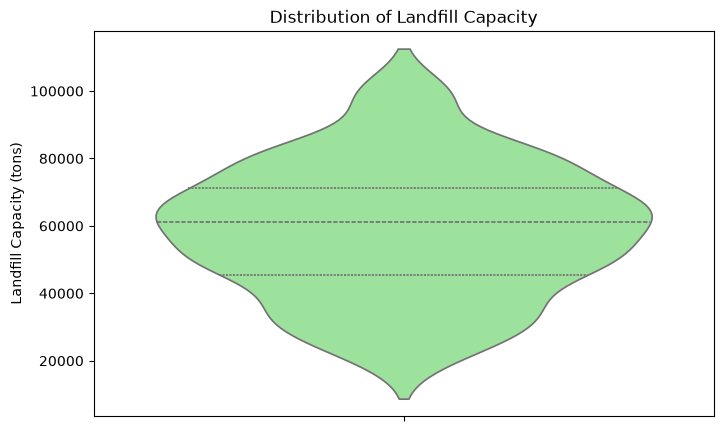

In [23]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=plastic_data,
    y='landfill_capacity_(tons)',
    color='lightgreen',
    inner='quartile'
)

plt.title('Distribution of Landfill Capacity')
plt.ylabel('Landfill Capacity (tons)')
plt.show()

* Most of the places have the landfill capasity of 62000
* Limited number of places have the landfill capacity less than 20000 and greater than 1 lakh
* Most of the places have the landfil capasity ~45000 to ~70000

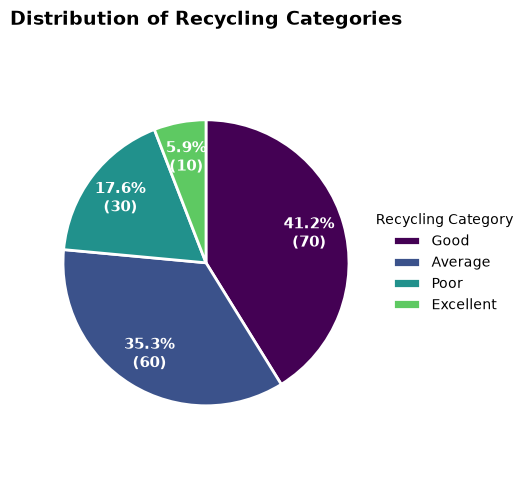

In [28]:
# Get counts and sort by frequency (largest slice first)
counts = plastic_data['recycling_category'].value_counts().sort_values(ascending=False)

# Use viridis colormap to match your original style
colors = plt.cm.viridis([i / len(counts) for i in range(len(counts))])

fig, ax = plt.subplots(figsize=(5, 5))

wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=None,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * counts.sum() / 100))})',
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    pctdistance=0.75,
    textprops={'fontsize': 11, 'weight': 'bold', 'color': 'white'}
)

# Legend instead of crowded labels
ax.legend(
    wedges,
    counts.index,
    title='Recycling Category',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.set_title('Distribution of Recycling Categories',
             fontsize=14, weight='bold', pad=15)

ax.axis('equal')  # Ensure the pie is circular
plt.tight_layout()
plt.show()

* 5.9% of cities (10 nos) shows excellent recycling rates
* 41.2% of cities (70 nos) shows good Recycling rate
* 35.3% of cities (60 nos) shows average Recycling rate
* 17.6% of cities (30 nos) shows poor recycling rate

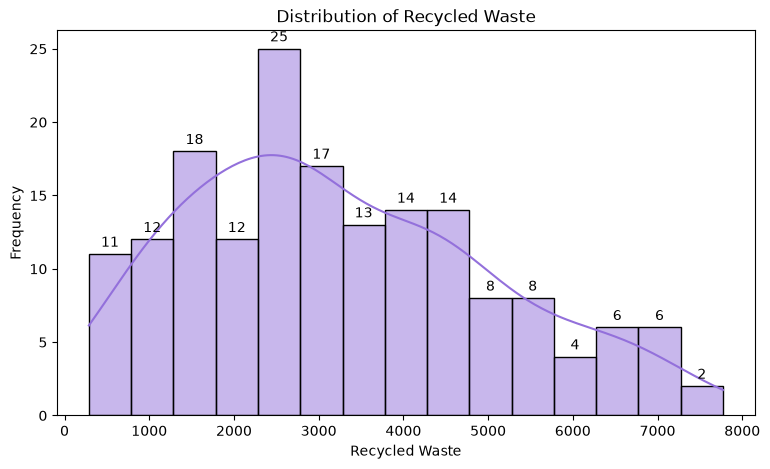

In [30]:
plt.figure(figsize=(9, 5))

ax=sns.histplot(
    data=plastic_data,
    x='recycled_waste',
    bins=15,
    kde=True,
    color='mediumpurple'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Distribution of Recycled Waste')
plt.xlabel('Recycled Waste')
plt.ylabel('Frequency')
plt.show()

* The most common recycled-waste quantity is 25000, around 25 cities
* Recycled waste is concentrated in lowest ranges.

### Bivariate Analysis

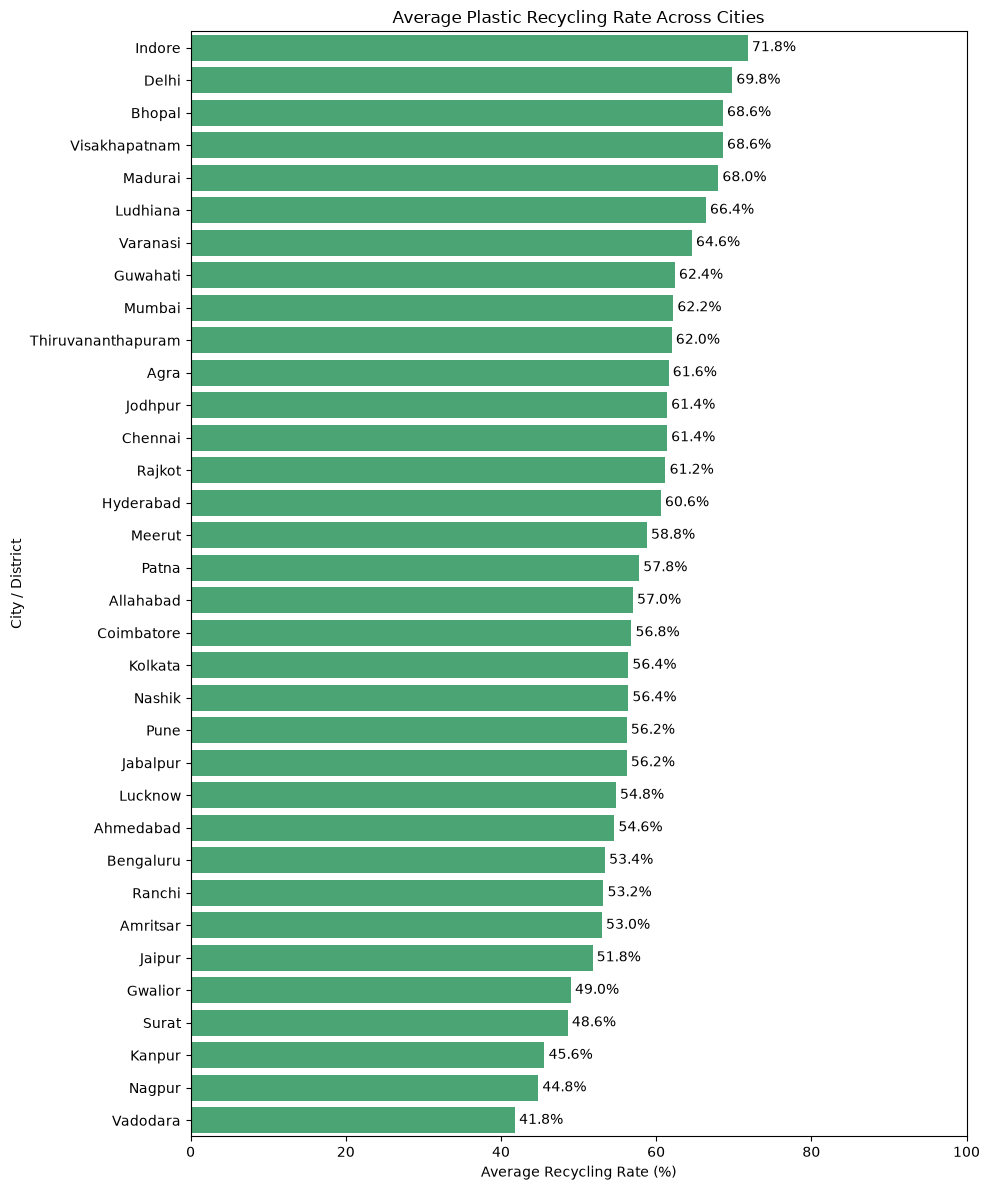

In [45]:
city_recycling = (
    plastic_data.groupby('city/district')['recycling_rate_(%)']
    .mean()
    .reset_index(name='average_recycling_rate')
    .sort_values('average_recycling_rate', ascending=False)
)


plt.figure(figsize=(10, 12))

ax = sns.barplot(
    data=city_recycling,
    x='average_recycling_rate',
    y='city/district',
    color='mediumseagreen'
)

plt.title('Average Plastic Recycling Rate Across Cities')
plt.xlabel('Average Recycling Rate (%)')
plt.ylabel('City / District')
plt.xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.show()

* Indore shows the highest average recycling rate - 71.8%, followed by Delhi - 69.8%, Bhopal and Visakhapatnam - 68.6%, and Madurai - 68.0%
* Vadodara shows the lowest average recycling rate - 41.8%, followed by Nagpur - 44.8% and Kanpur - 45.6%
* All 34 cities have an average recycling rate above 40%
* The gap between the best and worst city is about 30 percentage points
* 15 of 34 cities have an average rate above 60%, while only 5 cities are below 50%

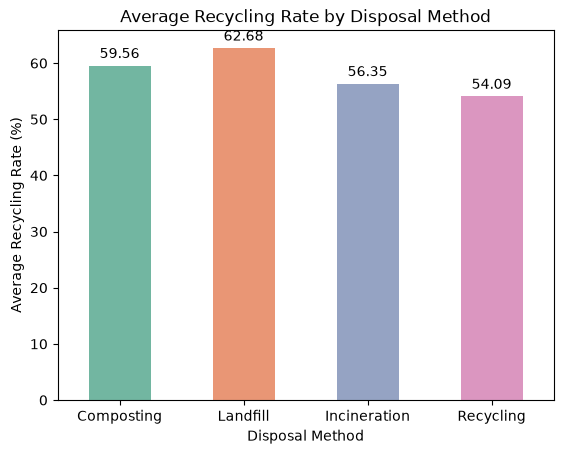

In [46]:
ax=sns.barplot(
    data=plastic_data,
    x='disposal_method',
    y='recycling_rate_(%)',
    errorbar=None,
    width=0.5,
    palette='Set2',
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')

plt.title('Average Recycling Rate by Disposal Method')
plt.xlabel('Disposal Method')
plt.ylabel('Average Recycling Rate (%)')
plt.show()

* Landfill shows the highest average recycling rate - 62.68%
* Composting - 59.56%, Incineration - 56.35%
* Recycling shows the lowest average recycling rate - 54.09%
* The gap between the highest and lowest method is 8.6 percentage points
* Records labelled as Recycling method do not show the best recycling rates, which is unexpected

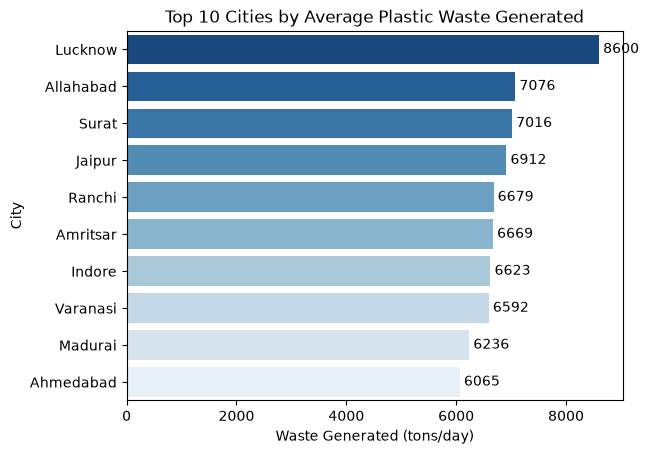

In [50]:
city_waste = (
    plastic_data.groupby('city/district')['waste_generated_(tons/day)']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

ax=sns.barplot(
    data=city_waste.head(10),
    x='waste_generated_(tons/day)',
    y='city/district',
    palette='Blues_r'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.0f')

plt.title('Top 10 Cities by Average Plastic Waste Generated')
plt.xlabel('Waste Generated (tons/day)')
plt.ylabel('City')
plt.show()

* Lucknow generates the highest plastic waste - 8600 tons/day, about 1500 tons/day more than Allahabad (7076)
* Surat (7016), Jaipur (6912), Ranchi (6679) and Amritsar (6669) follow
* All top 10 cities generate more than 6000 tons/day
* Indore, Varanasi and Madurai combine high waste generation with high recycling rates (71.8%, 64.6% and 68.0%)
* Surat, Jaipur, Ranchi and Amritsar generate high waste but recycle only about 49% to 53%

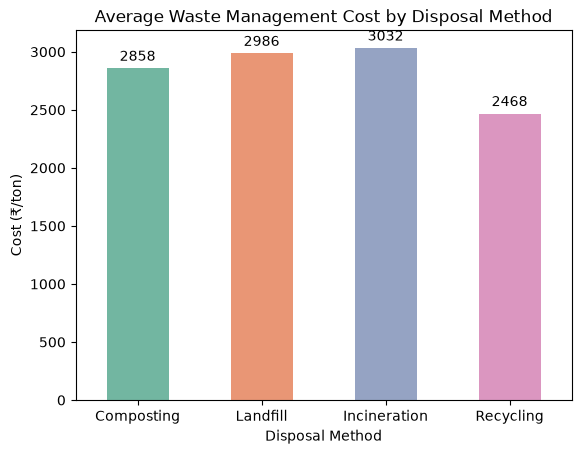

In [51]:
ax=sns.barplot(
    data=plastic_data,
    x='disposal_method',
    y='cost_of_waste_management_(₹/ton)',
    errorbar=None,
    width=0.5,
    palette='Set2',
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.0f')

plt.title('Average Waste Management Cost by Disposal Method')
plt.xlabel('Disposal Method')
plt.ylabel('Cost (₹/ton)')
plt.show()

* Recycling is the cheapest disposal method - ₹2468 per ton
* Incineration is the most expensive - ₹3032 per ton, followed by Landfill - ₹2986 and Composting - ₹2858
* Recycling costs about ₹564 per ton (18.6%) less than Incineration
* Recycling is cheapest but its records show the lowest average recycling rate

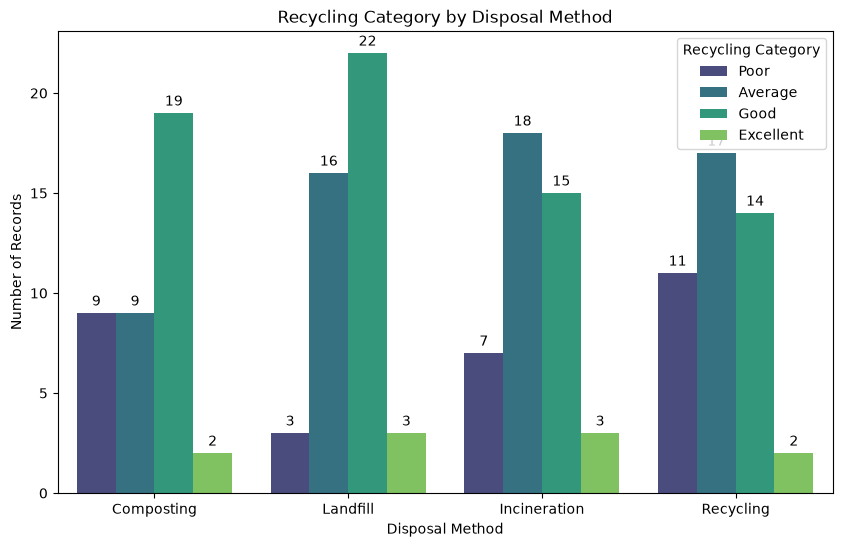

In [52]:
plt.figure(figsize=(10, 6))
ax=sns.countplot(
    data=plastic_data,
    x='disposal_method',
    hue='recycling_category',
    hue_order=['Poor','Average','Good','Excellent'],
    palette='viridis'
)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')

plt.title('Recycling Category by Disposal Method')
plt.xlabel('Disposal Method')
plt.ylabel('Number of Records')
plt.legend(title='Recycling Category')
plt.show()

* Landfill has the most Good records (22) and only 3 Poor records
* Recycling has the most Poor records (11) and the fewest Good records (14)
* Incineration and Recycling are dominated by the Average category (18 and 17)
* Composting has 9 Poor records, much higher than Landfill
* Excellent category is rare under every method - only 2 or 3 records

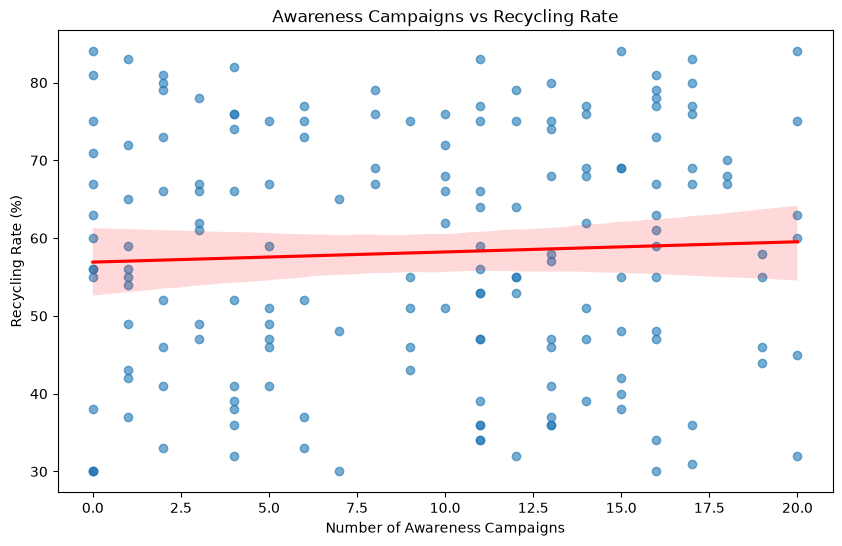

In [61]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=plastic_data,
    x='awareness_campaigns_count',
    y='recycling_rate_(%)',
    scatter_kws={'alpha':0.6},
    line_kws={'color':'red'}
)

plt.title('Awareness Campaigns vs Recycling Rate')
plt.xlabel('Number of Awareness Campaigns')
plt.ylabel('Recycling Rate (%)')
plt.show()

* Recycling rate rises very slightly with the number of awareness campaigns - from about 57% (0 campaigns) to about 59.5% (20 campaigns)
* Points are widely scattered - both high and low recycling rates occur at every campaign level
* Records with zero campaigns still reach rates up to 84%
* Awareness campaigns show only a weak influence on recycling rate

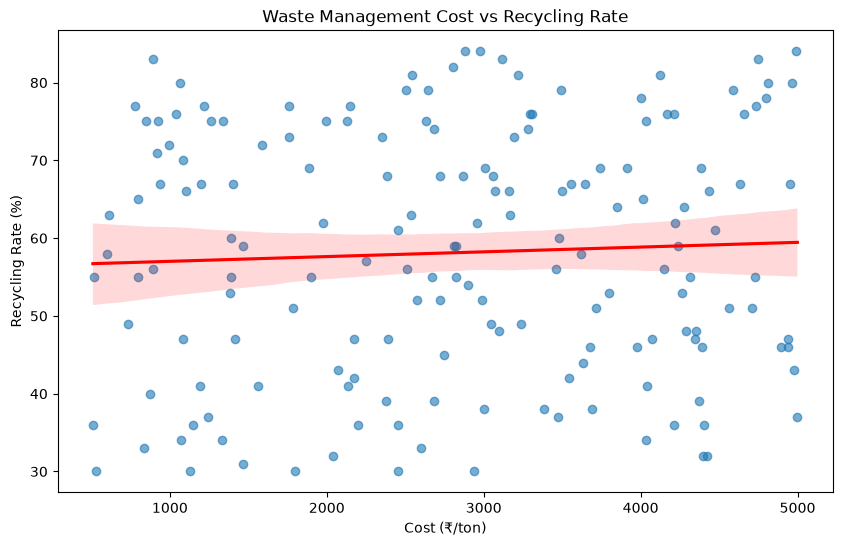

In [62]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=plastic_data,
    x='cost_of_waste_management_(₹/ton)',
    y='recycling_rate_(%)',
    scatter_kws={'alpha':0.6},
    line_kws={'color':'red'}
)

plt.title('Waste Management Cost vs Recycling Rate')
plt.xlabel('Cost (₹/ton)')
plt.ylabel('Recycling Rate (%)')
plt.show()

* The trend line is almost flat - about 56.7% at low cost to 59.4% at high cost
* Low-cost records (below ₹1500) range from 30% to 83% recycling rate
* High-cost records (above ₹4000) also range from 30% to 84%
* Spending more per ton does not guarantee a better recycling rate

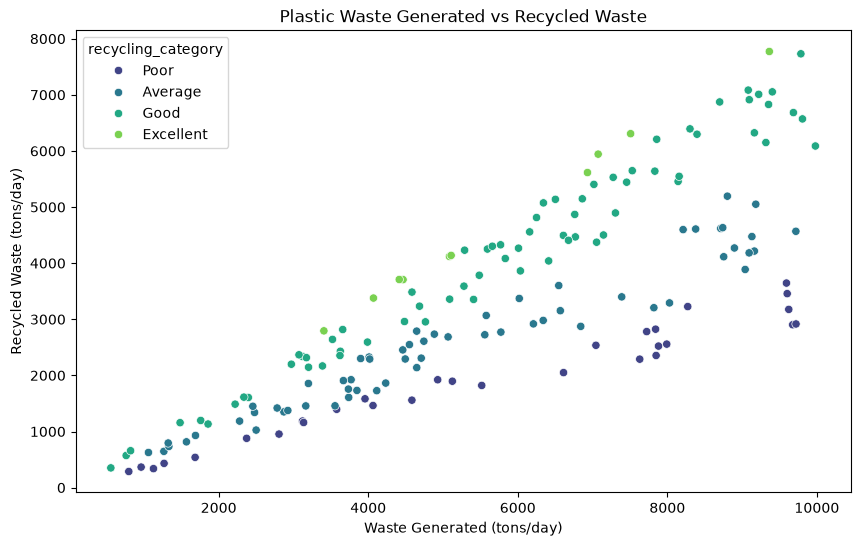

In [56]:
#Waste generated vs recycled waste
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plastic_data,
    x='waste_generated_(tons/day)',
    y='recycled_waste',
    hue='recycling_category',
    hue_order=['Poor','Average','Good','Excellent'],
    palette='viridis'
)

plt.title('Plastic Waste Generated vs Recycled Waste')
plt.xlabel('Waste Generated (tons/day)')
plt.ylabel('Recycled Waste (tons/day)')
plt.show()

* Recycled waste increases strongly with waste generated
* Good and Excellent records form the upper band, Poor and Average records form the lower band
* At 8000 to 10000 tons/day generated, recycled waste ranges from about 2900 to 7800 tons/day
* The recycling rate, not the volume of waste, decides how much is actually recycled

### Multivariate Analysis

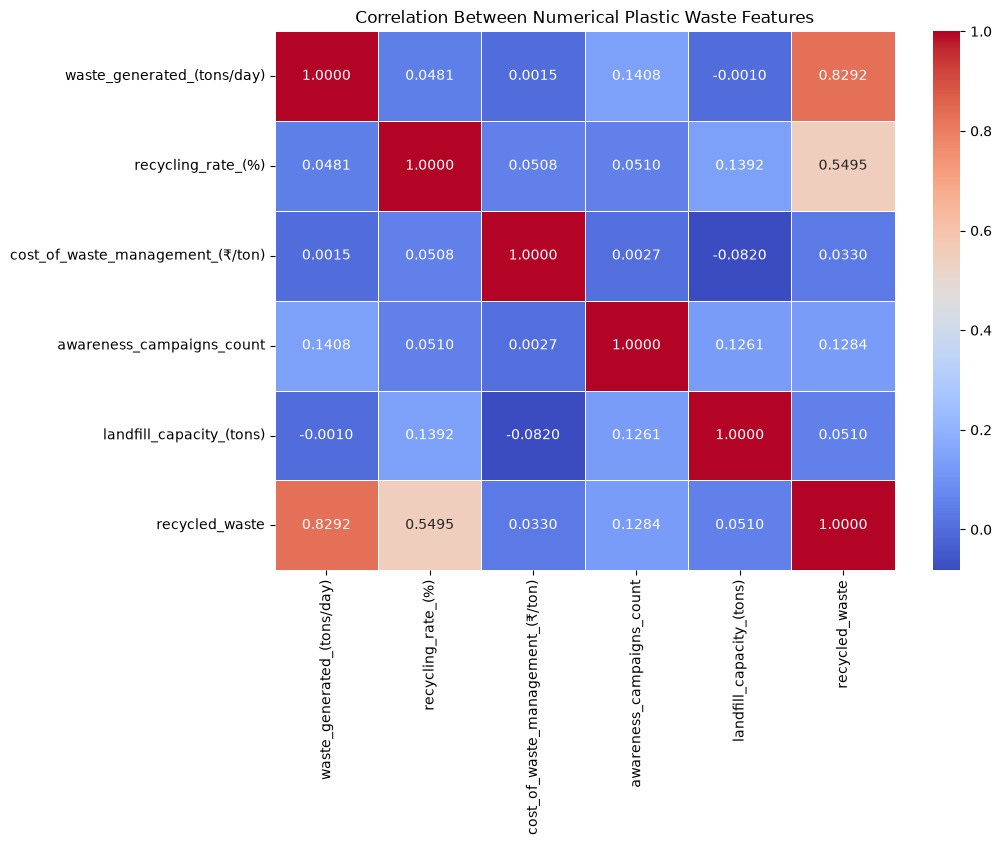

In [64]:
plt.figure(figsize=(10, 7))

corr = plastic_data[
    [
        'waste_generated_(tons/day)',
        'recycling_rate_(%)',
        'cost_of_waste_management_(₹/ton)',
        'awareness_campaigns_count',
        'landfill_capacity_(tons)',
        'recycled_waste'
    ]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical Plastic Waste Features')
plt.show()

* The strongest relationship is between waste generated and recycled waste, with a correlation of 0.8292
* Recycling rate and recycled waste are moderately correlated - 0.5495 (both are expected, as recycled waste is calculated from them)
* Waste generated and recycling rate are almost uncorrelated - 0.0481
* Cost of waste management has almost no relationship with any feature - the highest is -0.0820 with landfill capacity

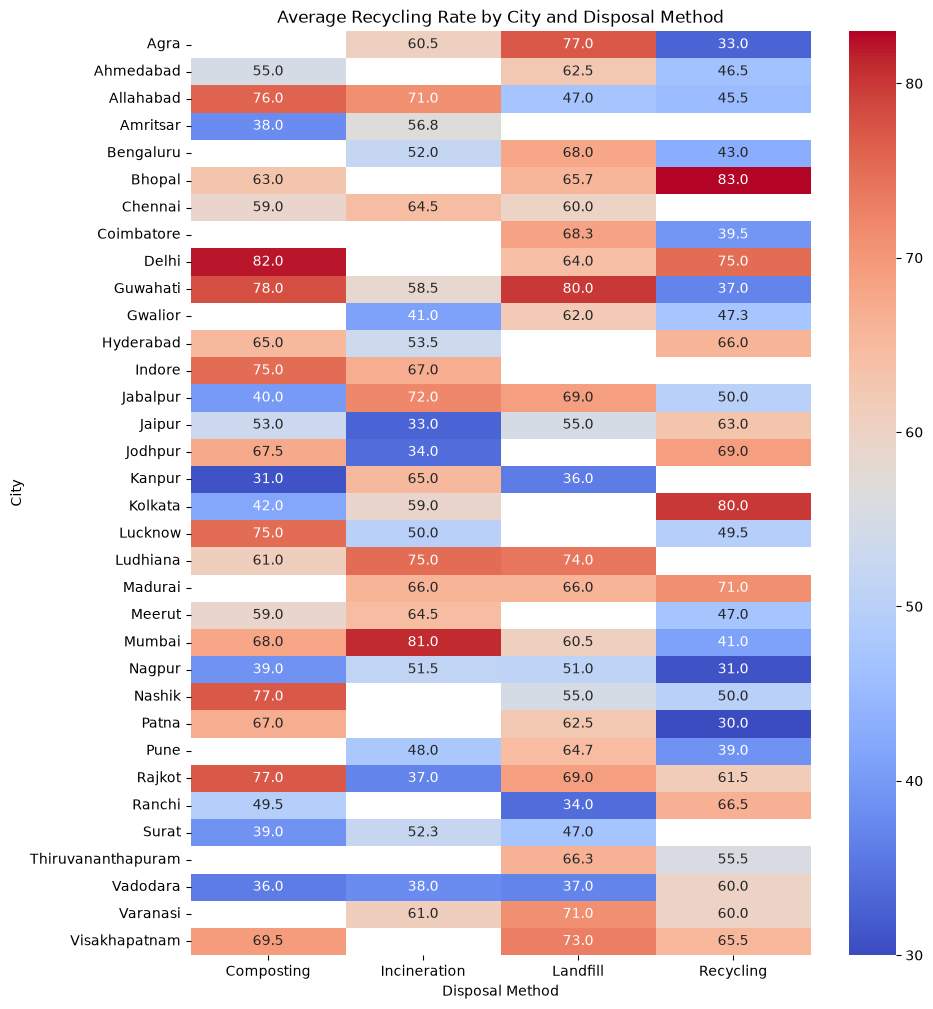

In [59]:
pivot_data = plastic_data.pivot_table(
    index='city/district',
    columns='disposal_method',
    values='recycling_rate_(%)',
    aggfunc='mean'
)

plt.figure(figsize=(10, 12))
sns.heatmap(
    pivot_data,
    annot=True,
    cmap='coolwarm',
    fmt='.1f'
)

plt.title('Average Recycling Rate by City and Disposal Method')
plt.xlabel('Disposal Method')
plt.ylabel('City')
plt.show()

* Highest city-method rates: Bhopal - Recycling (83), Delhi - Composting (82), Mumbai - Incineration (81), Kolkata - Recycling (80), Guwahati - Landfill (80)
* Lowest city-method rates: Patna - Recycling (30), Nagpur - Recycling (31), Kanpur - Composting (31), Jaipur - Incineration (33), Agra - Recycling (33)
* The same city varies widely by method - Guwahati: 80 (Landfill) vs 37 (Recycling); Mumbai: 81 (Incineration) vs 41 (Recycling)
* Vadodara stays low (36 to 38) in three of four methods

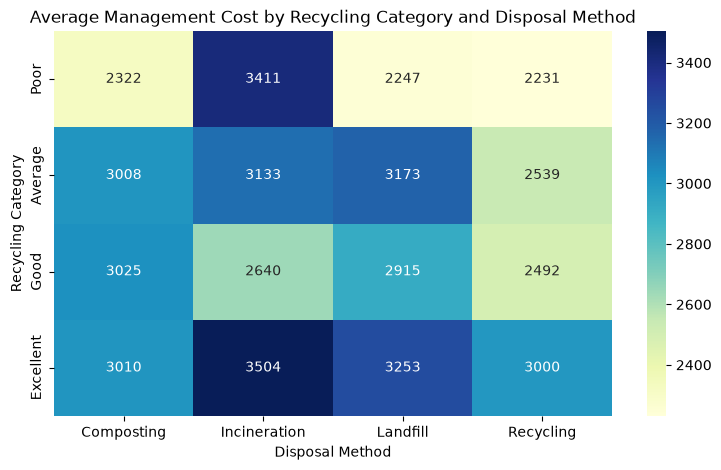

In [60]:
pivot_cost = plastic_data.pivot_table(
    index='recycling_category',
    columns='disposal_method',
    values='cost_of_waste_management_(₹/ton)',
    aggfunc='mean',
    observed=False
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    pivot_cost,
    annot=True,
    cmap='YlGnBu',
    fmt='.0f'
)

plt.title('Average Management Cost by Recycling Category and Disposal Method')
plt.xlabel('Disposal Method')
plt.ylabel('Recycling Category')
plt.show()

* Recycling is the cheapest method in every recycling category
* Incineration is the most expensive - ₹3504 for Excellent and ₹3411 for Poor records
* Poor records under Recycling (₹2231), Landfill (₹2247) and Composting (₹2322) have the lowest costs
* Excellent records cost ₹3000 or more under every method, but this is based on only 10 records
* Lower cost does not mean lower recycling performance, which matches the weak correlation seen earlier

## Conclusion

* Plastic waste generation varies significantly across cities, with some generating nearly 10,000 tons per day.
* The overall average recycling rate is approximately 58.14%, indicating scope for improvement.
* Indore has the highest average recycling rate (71.8%), while Vadodara has the lowest (41.8%).
* Lucknow generates the highest average plastic waste at approximately 8,600 tons per day.
* Recycling is the most economical disposal method at ₹2,468 per ton, but it does not show the highest average recycling rate.
* Awareness campaigns and waste management costs show only a weak relationship with recycling performance.
* Waste generation and recycling rate are the major factors determining the quantity of plastic waste recycled.
* Recycling performance varies across cities and disposal methods, highlighting the need for city-specific waste management strategies.